# Fase 3: estimación y features
El filtro combina el balance nominal con la medición del día. El cálculo del error usa la verdad solo como diagnóstico.

RMSE sensor: 0.018771641959520025
RMSE Kalman: 0.013139942376420514
Features del modelo: ['theta_est_t', 'delta_theta', 'dist_umbral', 'etc_est', 'lluvia_pron_24h', 'riego_t', 'dias_desde_ultimo_riego']


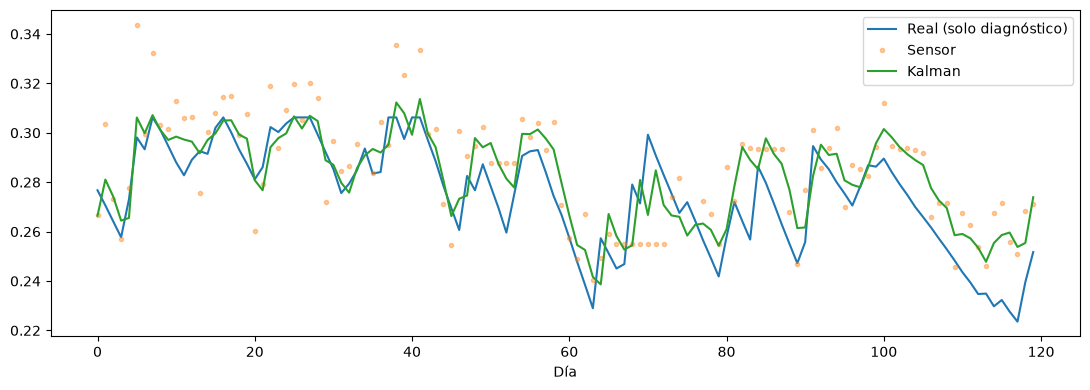

In [1]:
# Configurar imports para la fase de estimación.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.simulator import simulate
from src.features import make_features, FEATURES

# Crear una serie y calcular features observables por zona.
observed, truth, _ = simulate(seed=7, return_truth=True)
zone = observed.zona_id == 0
features = make_features(observed)
estimated = features.loc[zone, 'theta_est_t'].to_numpy()
raw = observed.loc[zone, 'theta_obs'].to_numpy()
actual = truth.loc[zone, 'theta_real'].to_numpy()
# Usar la verdad solo para comprobar el error del observador.
print('RMSE sensor:', np.sqrt(np.nanmean((raw-actual)**2)))
print('RMSE Kalman:', np.sqrt(np.mean((estimated-actual)**2)))
print('Features del modelo:', FEATURES)
# Visualizar medición, estado filtrado y verdad de referencia.
plt.figure(figsize=(11,4)); plt.plot(actual,label='Real (solo diagnóstico)'); plt.plot(raw,'.',alpha=.4,label='Sensor'); plt.plot(estimated,label='Kalman'); plt.legend(); plt.xlabel('Día'); plt.tight_layout()